> **A CHEM 438 final project from fall 2025**, shared as an example with the author's name removed. It used the student's own base-pair scores for RNA structures in the PDB. The data files are not included, so the cells will not rerun here: read it top to bottom, the figures and results are saved in the notebook.


In [1]:
!pip install rdkit
!pip install py3dmol

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 29.1/29.1 MB 13.4 MB/s eta 0:00:00a 0:00:01


In [2]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import numpy as np
from IPython.display import Image, display
from rdkit import Chem
from rdkit.Chem import AllChem
from rdkit.Chem import Draw
import py3Dmol
from rdkit.Chem.Draw import rdMolDraw2D
from rdkit.Chem.Draw import IPythonConsole
IPythonConsole.molSize = 200,200
from typing import Dict
from scipy.stats import linregress
from matplotlib.lines import Line2D
from matplotlib.patches import Patch


In [3]:
#CSV definitions
scores_df = pd.read_csv('rna_scores.csv')
motifs_df = pd.read_csv('exclude_motif_list.csv')
motifs_scores = pd.read_csv('scores_motifs_summary.csv')

#Computational Validation of RNA Base Pair Quality

##RNAs and why their structure matters

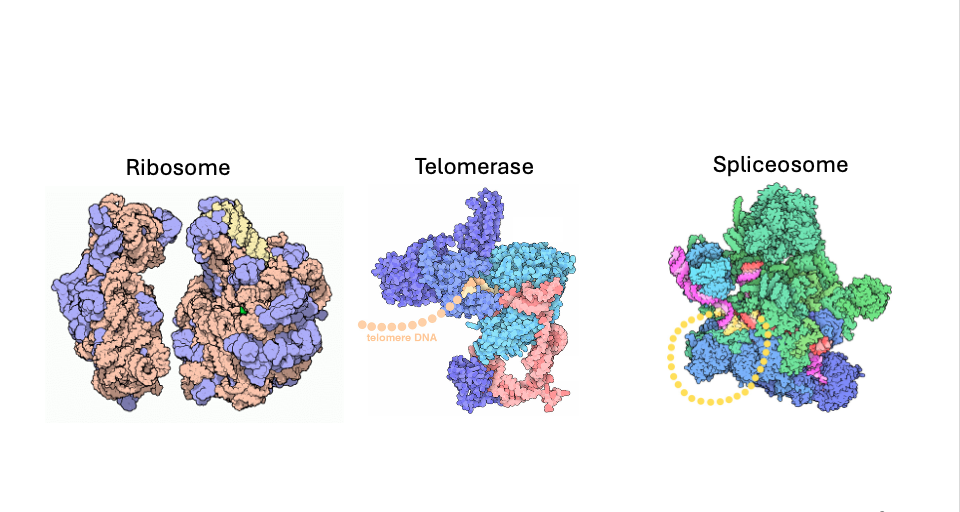

In [4]:
## Images
image_path = "RNAs.png"
img = Image(filename=image_path, width=1000, height=500)
display(img)

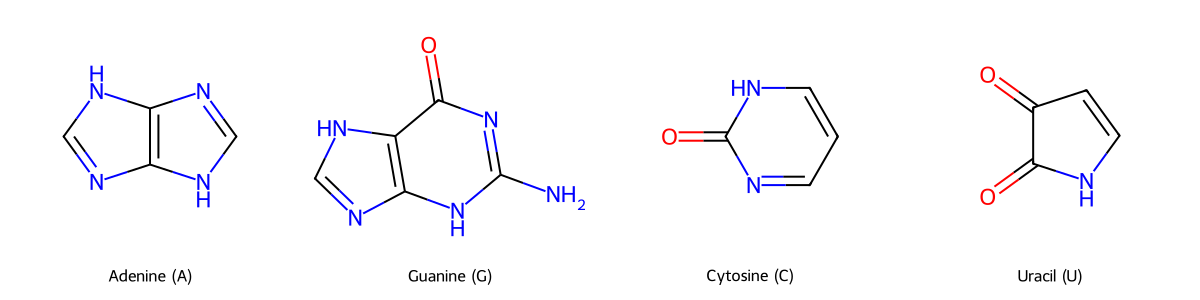

In [5]:
structures = {
    "Adenine (A)": "C1=NC2=C(N1)N=CN2",
    "Guanine (G)": "C1=NC2=C(N1)C(=O)N=C(N2)N",
    "Cytosine (C)": "C1=NC(=O)NC=C1",
    "Uracil (U)": "O=C1NC=CC1=O",
    }

molecules = [Chem.MolFromSmiles(smiles) for smiles in structures.values()]

Draw.MolsToGridImage(
    molecules,
    molsPerRow=4,
    subImgSize=(300,300),
    legends=list(structures.keys())
)

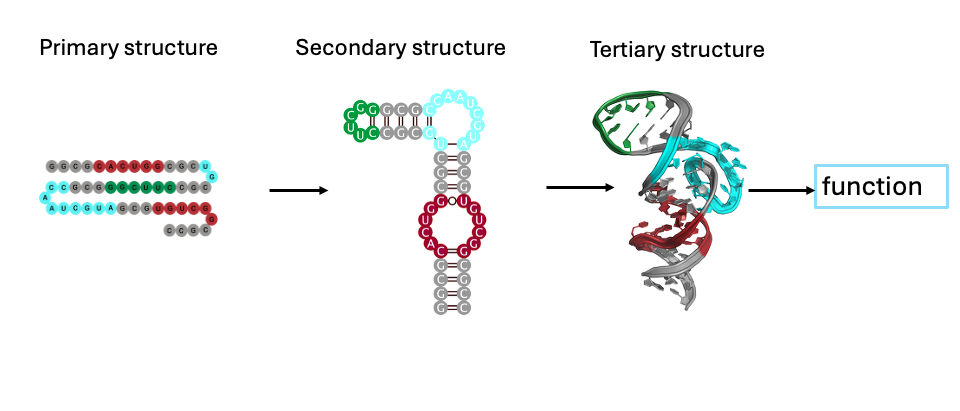

In [6]:
## RNA structure Imges
image_path = "structures.png"
img = Image(filename=image_path, width=1000, height=500)
display(img)

## The Protein Data Bank (PDB)
The Protein Data Bank is the global repository for 3D structural data of biological macromolecules (proteins, DNA, RNA, and complexes).

In [7]:
view = py3Dmol.view(width=600, height=600, query='pdb:1y26')
view.setStyle({"cartoon":{}})
view.show()

3Dmol.js failed to load for some reason. Please check your browser console for error messages.

### The Problem -  Poor refinement in deposited structures

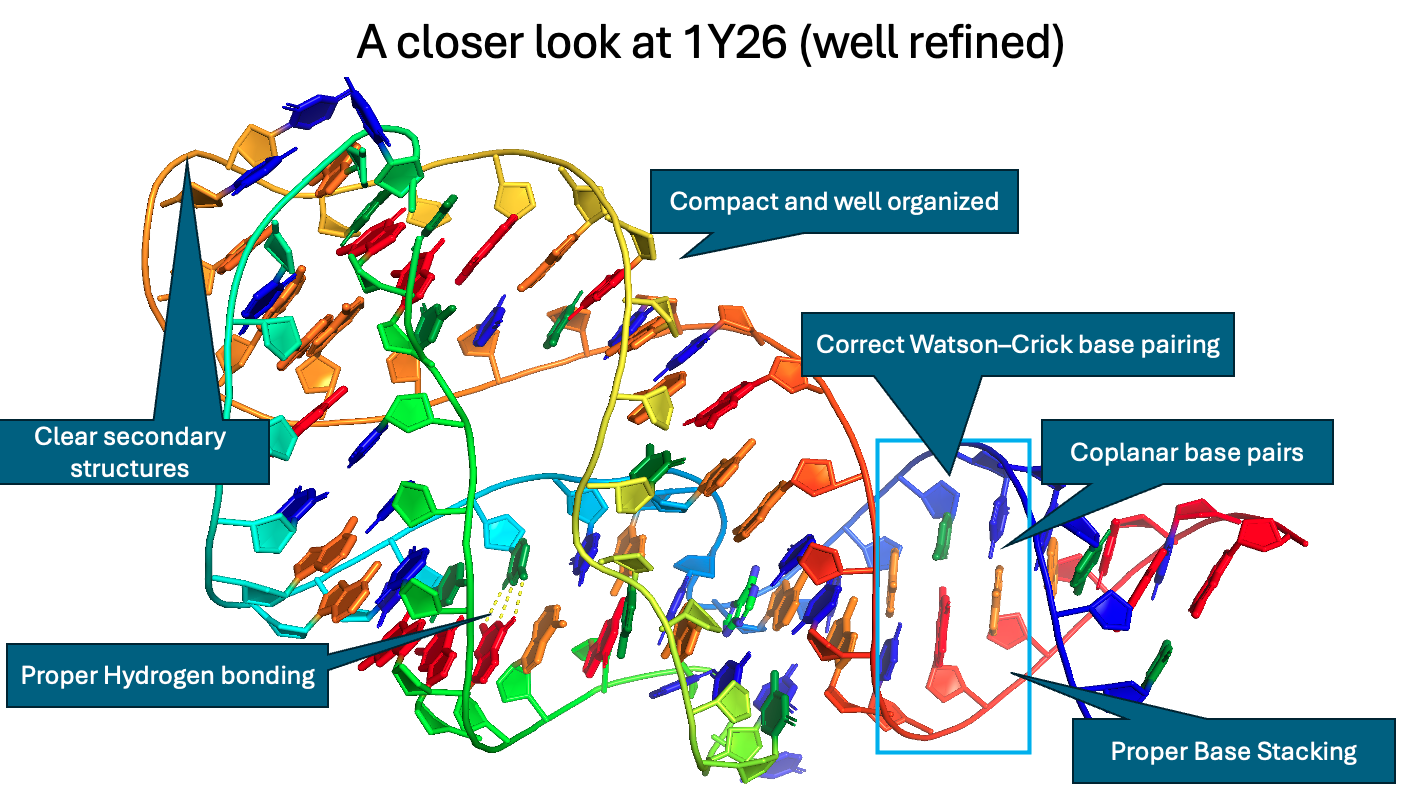

In [8]:
## RNA structure Imges
image_path = "1y26.png"
img = Image(filename=image_path, width=1100, height=600)
display(img)

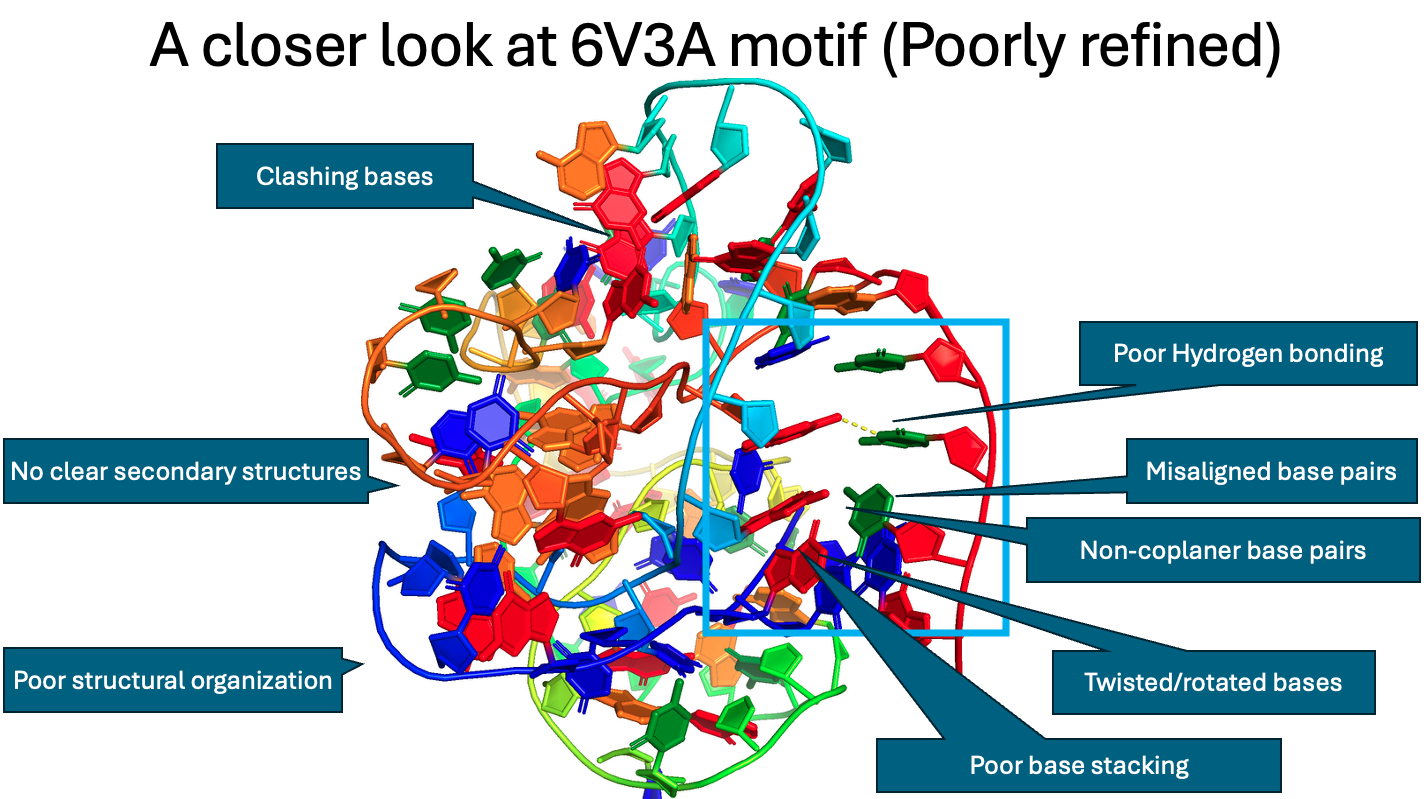

In [9]:
## RNA structure Imges
image_path = "poor_motif.png"
img = Image(filename=image_path, width=1000, height=600)
display(img)

### The Need for automated quality assessment

## Hypotheses
1. Automated scoring of base-pair geometry can identify refinement targets with high specificity.

2. Base-pair quality scores of RNA's are size-independent

3. Base-pair quality scores provide complementary information to existing validation metrics

## Results and findings


#### 1. Scores distributions of all RNA's

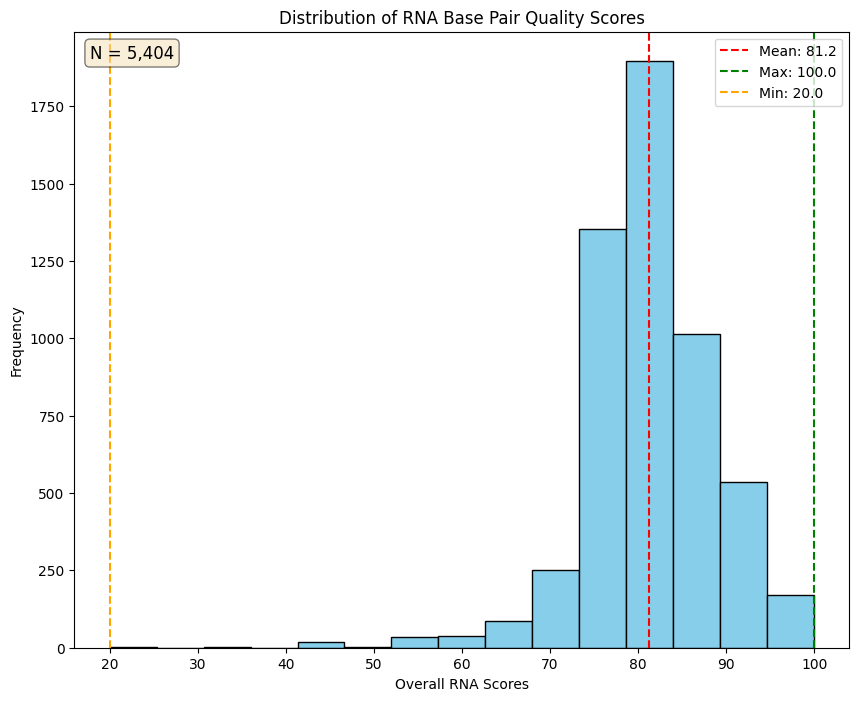

In [10]:
mean_score = scores_df['Overall_Score'].mean()
max_score = scores_df['Overall_Score'].max()
min_score = scores_df['Overall_Score'].min()
mid_score = scores_df['Overall_Score'].median()
sample_size = len(scores_df['Overall_Score'].dropna())

fig, ax = plt.subplots(figsize=(10, 8))
ax.hist(scores_df['Overall_Score'].dropna(), bins=15, edgecolor='black', color='skyblue')
ax.set_xlabel('Overall RNA Scores')
ax.set_ylabel('Frequency')
ax.set_title('Distribution of RNA Base Pair Quality Scores')

ax.axvline(mean_score, color='red', linestyle='--', label=f'Mean: {mean_score:.1f}')
ax.axvline(max_score, color='green', linestyle='--', label=f'Max: {max_score:.1f}')
ax.axvline(min_score, color='orange', linestyle='--', label=f'Min: {min_score:.1f}')

legend1 = ax.legend(loc='upper right')
stats_text = f'N = {sample_size:,}'
props = dict(boxstyle='round', facecolor='wheat', alpha=0.5)
ax.text(0.02, 0.98, stats_text, transform=ax.transAxes, fontsize=12,
        verticalalignment='top', bbox=props);

#### 2. Score distributions of all high quality RNA's

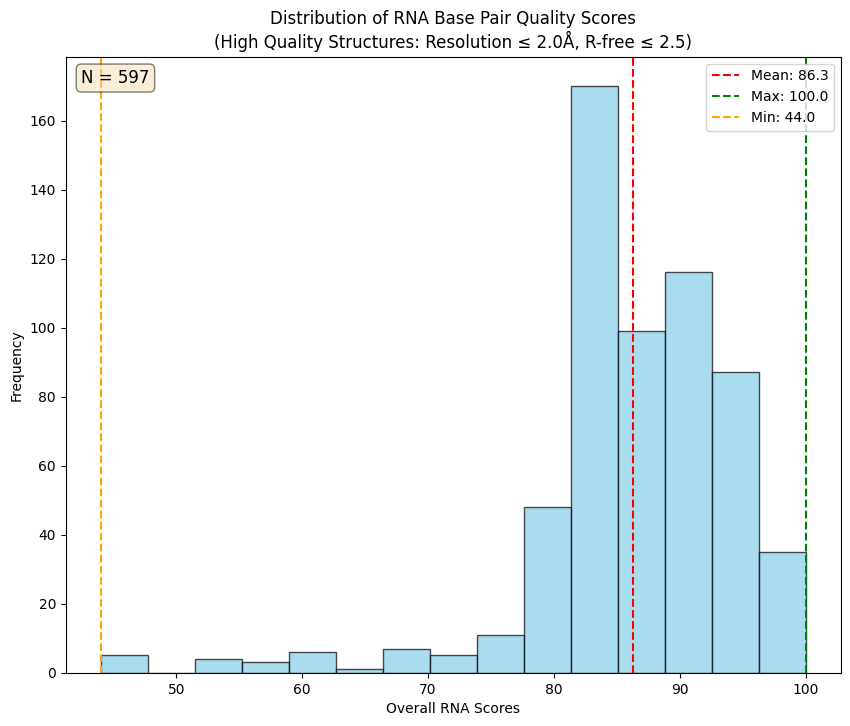

In [11]:
numeric_columns = ['Refinement_resolution', 'R_free', 'Overall_Score']
for col in numeric_columns:
    if col in scores_df.columns:
        scores_df[col] = scores_df[col].astype(str).str.strip()
        scores_df[col] = pd.to_numeric(scores_df[col].str.replace(r'[^0-9.\-]', '', regex=True), errors='coerce')

high_quality_scores = scores_df.query("Refinement_resolution <= 2.0 and R_free <= 2.5").copy()
scores_data = high_quality_scores['Overall_Score'].dropna().values

mean_score = np.mean(scores_data)
max_score = np.max(scores_data)
min_score = np.min(scores_data)


fig, ax = plt.subplots(figsize=(10, 8))
sample_size = len(scores_data)

ax.hist(scores_data, bins=15, edgecolor='black', color='skyblue', alpha=0.7)
ax.set_xlabel('Overall RNA Scores')
ax.set_ylabel('Frequency')
ax.set_title('Distribution of RNA Base Pair Quality Scores\n(High Quality Structures: Resolution ≤ 2.0Å, R-free ≤ 2.5)')

ax.axvline(mean_score, color='red', linestyle='--', label=f'Mean: {mean_score:.1f}')
ax.axvline(max_score, color='green', linestyle='--', label=f'Max: {max_score:.1f}')
ax.axvline(min_score, color='orange', linestyle='--', label=f'Min: {min_score:.1f}')

ax.legend(loc='upper right')
stats_text = f'N = {sample_size:,}'
props = dict(boxstyle='round', facecolor='wheat', alpha=0.5)
ax.text(0.02, 0.98, stats_text, transform=ax.transAxes, fontsize=12,
        verticalalignment='top', bbox=props);

#### 3. Are base-pair quality scores consistent across experimental methods?



Statistics by Experimental Method:
                                        count   mean  median   std   min  \
Experimental_method                                                        
ELECTRON MICROSCOPY                      2259  79.08    79.1  6.12  35.0   
X-RAY DIFFRACTION                        2990  82.70    82.7  7.76  20.0   
X-RAY DIFFRACTION, NEUTRON DIFFRACTION      1  81.50    81.5   NaN  81.5   

                                          max  
Experimental_method                            
ELECTRON MICROSCOPY                     100.0  
X-RAY DIFFRACTION                       100.0  
X-RAY DIFFRACTION, NEUTRON DIFFRACTION   81.5  


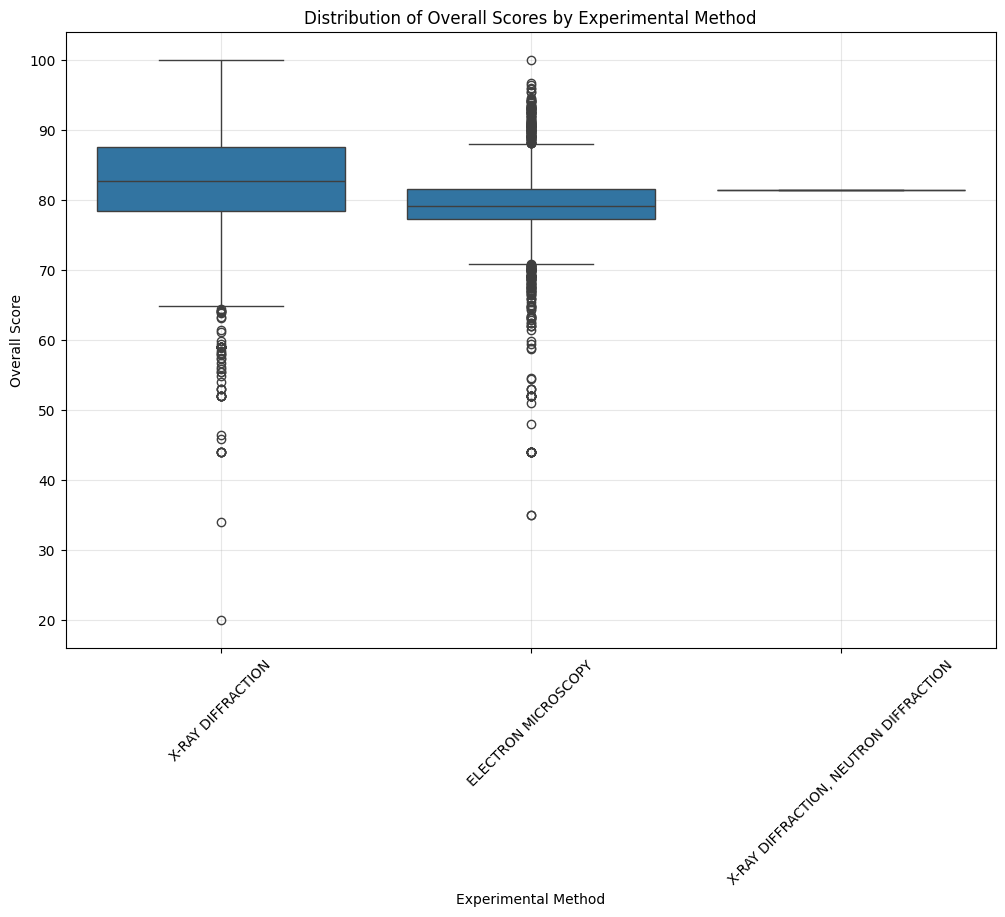

In [12]:
df_experiments = scores_df.dropna(subset=['Overall_Score', 'Experimental_method'])

plt.figure(figsize=(12, 8))
sns.boxplot(data=df_experiments, x='Experimental_method', y='Overall_Score')
plt.xlabel('Experimental Method')
plt.ylabel('Overall Score')
plt.title('Distribution of Overall Scores by Experimental Method')
plt.xticks(rotation=45)
plt.grid(True, alpha=0.3)

print("\nStatistics by Experimental Method:")
method_stats = df_experiments.groupby('Experimental_method')['Overall_Score'].agg([
    'count', 'mean', 'median', 'std', 'min', 'max'
]).round(2)
print(method_stats)

#### 4. What is the relationship between the Scores and established PDB quality metrics

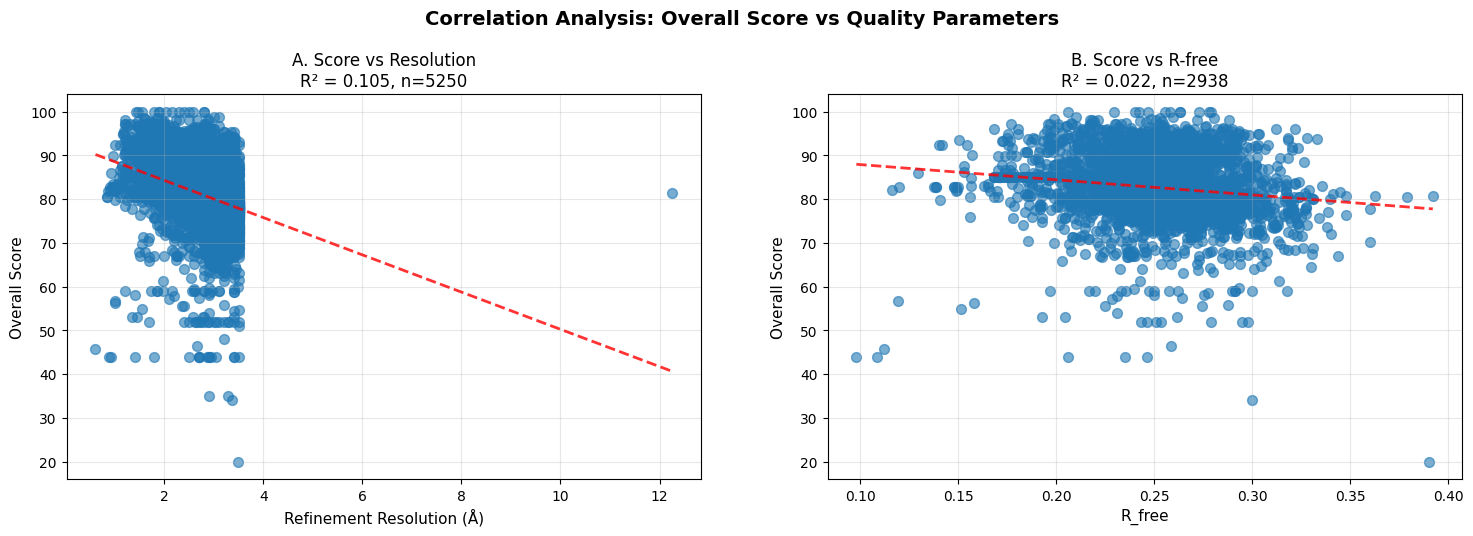

In [13]:
fig, axes = plt.subplots(1, 2, figsize=(18, 5))


scores_df['Refinement_resolution'] = pd.to_numeric(
    scores_df['Refinement_resolution'].astype(str).str.replace(',', '').str.split().str[0],
    errors='coerce'
)

df_plot2 = scores_df.dropna(subset=['Overall_Score', 'Refinement_resolution'])
correlation2 = df_plot2['Refinement_resolution'].corr(df_plot2['Overall_Score'])

ax2 = axes[0]
ax2.scatter(df_plot2['Refinement_resolution'], df_plot2['Overall_Score'], alpha=0.6, s=50)
ax2.set_xlabel('Refinement Resolution (Å)', fontsize=11)
ax2.set_ylabel('Overall Score', fontsize=11)
ax2.set_title(f'A. Score vs Resolution\nR² = {correlation2**2:.3f}, n={len(df_plot2)}', fontsize=12)
ax2.grid(True, alpha=0.3)


z2 = np.polyfit(df_plot2['Refinement_resolution'], df_plot2['Overall_Score'], 1)
x_range2 = np.array([df_plot2['Refinement_resolution'].min(), df_plot2['Refinement_resolution'].max()])
ax2.plot(x_range2, z2[0]*x_range2 + z2[1], 'r--', alpha=0.8, linewidth=2)


df_xray = scores_df.query("Experimental_method == 'X-RAY DIFFRACTION'")
df_plot3 = df_xray.dropna(subset=['Overall_Score', 'R_free'])

correlation3 = df_plot3['R_free'].corr(df_plot3['Overall_Score'])
result3 = linregress(df_plot3['R_free'], df_plot3['Overall_Score'])

ax3 = axes[1]
ax3.scatter(df_plot3['R_free'], df_plot3['Overall_Score'], alpha=0.6, s=50)
ax3.set_xlabel('R_free', fontsize=11)
ax3.set_ylabel('Overall Score', fontsize=11)
ax3.set_title(f'B. Score vs R-free\nR² = {correlation3**2:.3f}, n={len(df_plot3)}', fontsize=12)
ax3.grid(True, alpha=0.3)

z3 = np.polyfit(df_plot3['R_free'], df_plot3['Overall_Score'], 1)
x_range3 = np.array([df_plot3['R_free'].min(), df_plot3['R_free'].max()])
ax3.plot(x_range3, z3[0]*x_range3 + z3[1], 'r--', alpha=0.8, linewidth=2)

fig.suptitle('Correlation Analysis: Overall Score vs Quality Parameters', fontsize=14, fontweight='bold', y=1.05);

#### 5. Are the scores redundant with existing validation metrics, or do they provide new information

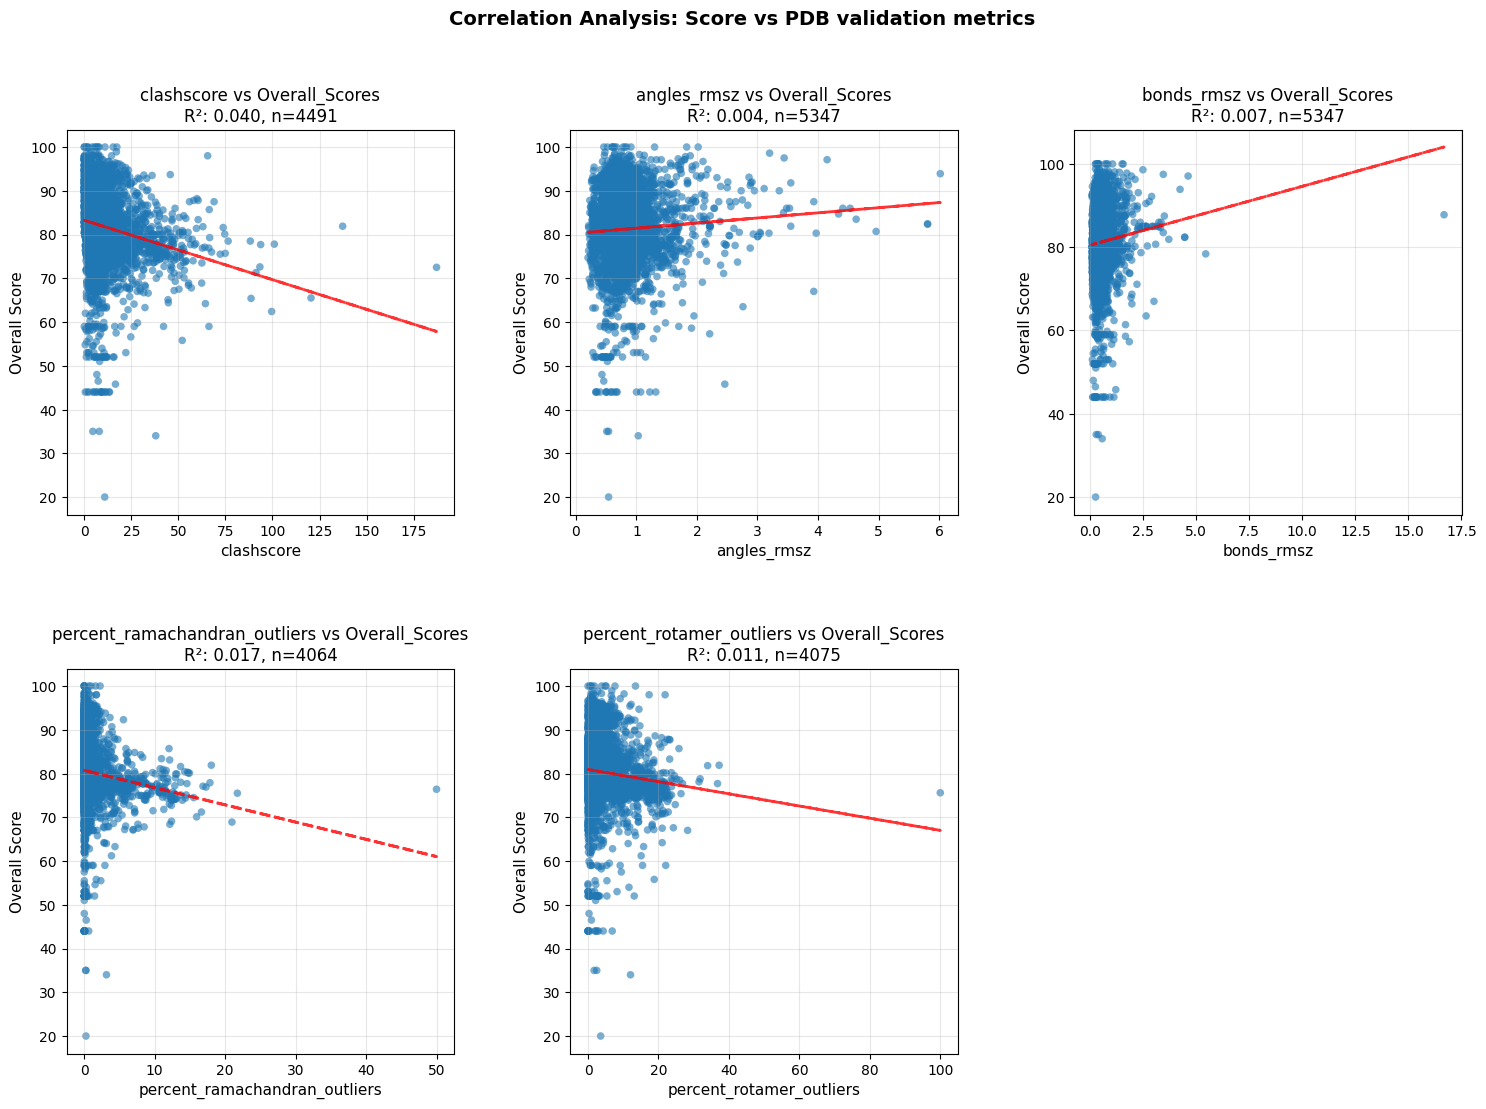

In [14]:
metrics = [
    ('clashscore', 'clashscore'),
    ('angles_rmsz', 'angles_rmsz'),
    ('bonds_rmsz', 'bonds_rmsz'),
    ('percent_ramachandran_outliers', 'percent_ramachandran_outliers'),
    ('percent_rotamer_outliers', 'percent_rotamer_outliers')
]

fig, axes = plt.subplots(2, 3, figsize=(18, 12))
axes = axes.flatten()

for i, (metric, xlabel) in enumerate(metrics):
    df_plot = scores_df.dropna(subset=['Overall_Score', metric])
    correlation = df_plot[metric].corr(df_plot['Overall_Score'])

    # Create scatter plot
    ax = axes[i]
    scatter = ax.scatter(df_plot[metric], df_plot['Overall_Score'], alpha=0.6, s=30, edgecolors='none')

    z = np.polyfit(df_plot[metric], df_plot['Overall_Score'], 1)
    p = np.poly1d(z)
    ax.plot(df_plot[metric], p(df_plot[metric]), "r--", alpha=0.8, linewidth=2)

    # Set labels and title
    ax.set_xlabel(xlabel, fontsize=11)
    ax.set_ylabel('Overall Score', fontsize=11)
    ax.set_title(f'{xlabel} vs Overall_Scores\nR²: {correlation**2:.3f}, n={len(df_plot)}', fontsize=12)
    ax.grid(True, alpha=0.3)

fig.delaxes(axes[5]);
plt.subplots_adjust(hspace=0.4, wspace=0.3);
fig.suptitle('Correlation Analysis: Score vs PDB validation metrics', fontsize=14, fontweight='bold');

#### 6. Is the scoring algorithm driven by actual base-pair quality or biased by RNA structure size?

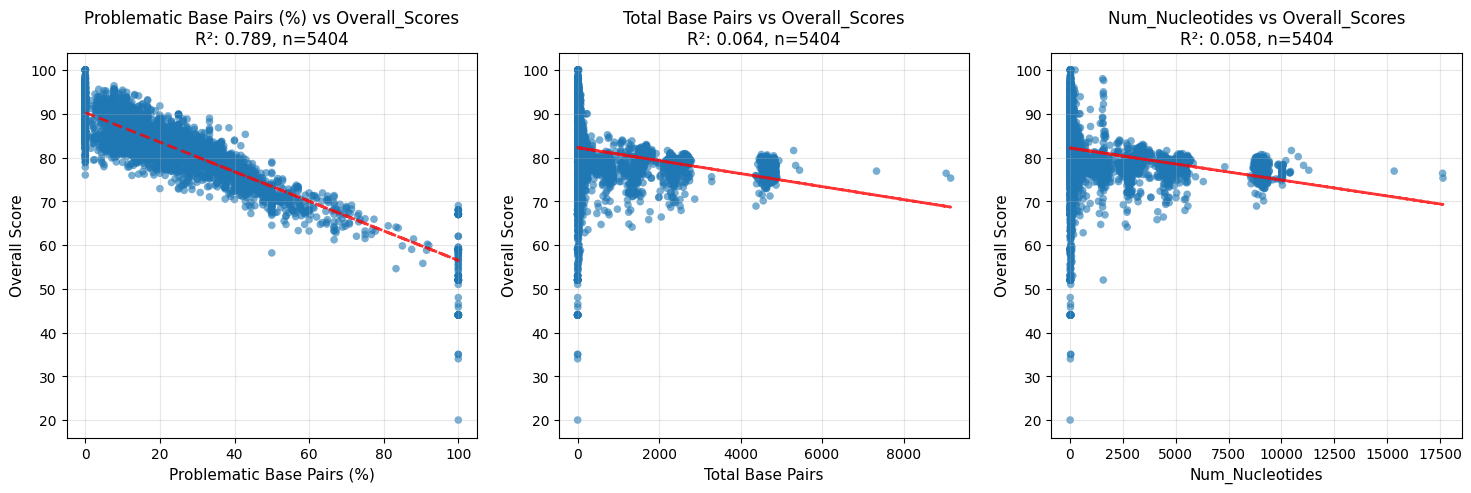

In [15]:
metrics = [
    ('Problematic_Percentage', 'Problematic Base Pairs (%)'),
    ('Total_Base_Pairs', 'Total Base Pairs'),
    ('Num_Nucleotides', 'Num_Nucleotides')

]

fig, axes = plt.subplots(1, 3, figsize=(18, 5))
axes = axes.flatten()

for i, (metric, xlabel) in enumerate(metrics):
    df_plot = scores_df.dropna(subset=['Overall_Score', metric])
    correlation = df_plot[metric].corr(df_plot['Overall_Score'])

    # Create scatter plot
    ax = axes[i]
    scatter = ax.scatter(df_plot[metric], df_plot['Overall_Score'], alpha=0.6, s=30, edgecolors='none')

    z = np.polyfit(df_plot[metric], df_plot['Overall_Score'], 1)
    p = np.poly1d(z)
    ax.plot(df_plot[metric], p(df_plot[metric]), "r--", alpha=0.8, linewidth=2)

    # Set labels and title
    ax.set_xlabel(xlabel, fontsize=11)
    ax.set_ylabel('Overall Score', fontsize=11)
    ax.set_title(f'{xlabel} vs Overall_Scores\nR²: {correlation**2:.3f}, n={len(df_plot)}', fontsize=12)
    ax.grid(True, alpha=0.3);

#### 7. Do visually identified poorly refined motifs show score degradation when isolated from their structural context?

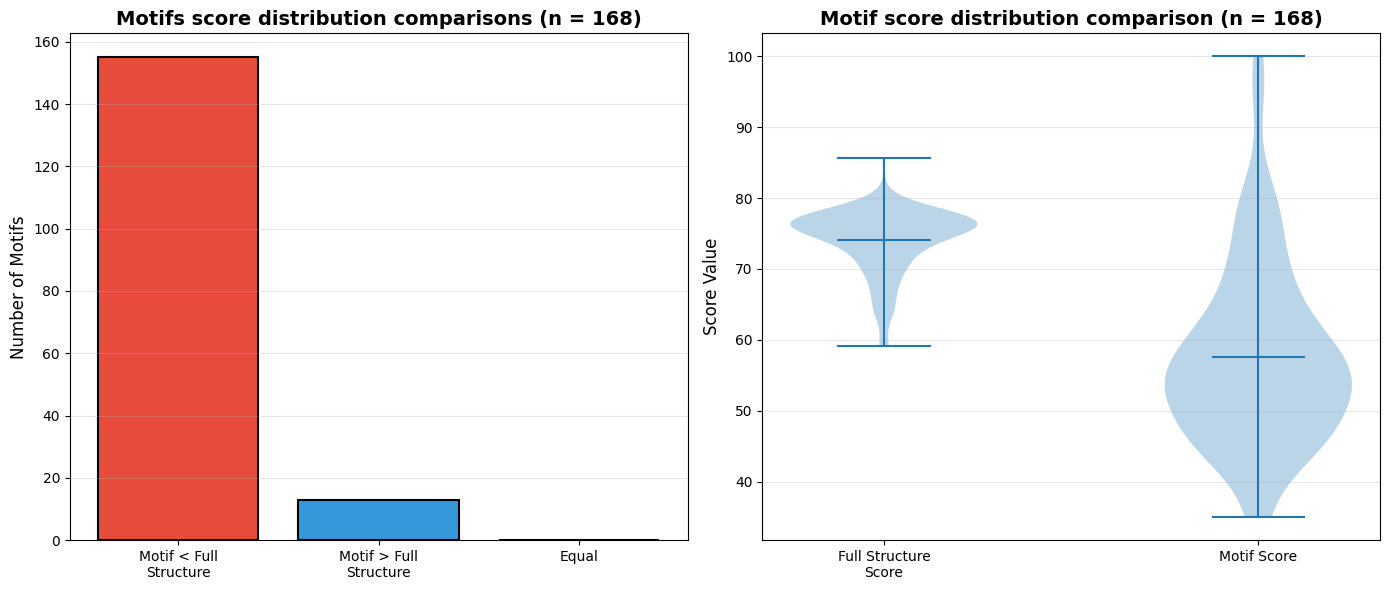

In [16]:
filtered_motifs_scores = motifs_scores[motifs_scores['Motif_Name'].isin(motifs_df['motif_id'])]

below_line = (filtered_motifs_scores['Motif_Score'] < filtered_motifs_scores['Full_Structure_Score']).sum()
above_line = (filtered_motifs_scores['Motif_Score'] > filtered_motifs_scores['Full_Structure_Score']).sum()
equal_line = (filtered_motifs_scores['Motif_Score'] == filtered_motifs_scores['Full_Structure_Score']).sum()

fig, axes = plt.subplots(1, 2, figsize=(14, 6))

ax1 = axes[0]
categories = ['Motif < Full\nStructure', 'Motif > Full\nStructure', 'Equal']
counts = [below_line, above_line, equal_line]
colors = ['#e74c3c', '#3498db', '#95a5a6']
bars = ax1.bar(categories, counts, color=colors, edgecolor='black', linewidth=1.5)
ax1.set_ylabel('Number of Motifs', fontsize=12)
ax1.set_title(f'Motifs score distribution comparisons (n = {len(filtered_motifs_scores)})', fontsize=14, fontweight='bold')
ax1.grid(True, alpha=0.3, axis='y')

ax2 = axes[1]
data_to_plot = [filtered_motifs_scores['Full_Structure_Score'],
                filtered_motifs_scores['Motif_Score']]
parts = ax2.violinplot(data_to_plot, positions=[1, 2], showmeans=True, showmedians=False)
ax2.set_xticks([1, 2])
ax2.set_xticklabels(['Full Structure\nScore', 'Motif Score'])
ax2.set_ylabel('Score Value', fontsize=12)
ax2.set_title(f'Motif score distribution comparison (n = {len(filtered_motifs_scores)})', fontsize=14, fontweight='bold')
ax2.grid(True, alpha=0.3, axis='y')

plt.tight_layout()

#### 8. Is score degradation specific to poorly refined motifs, or do all motifs lose scores when isolated?


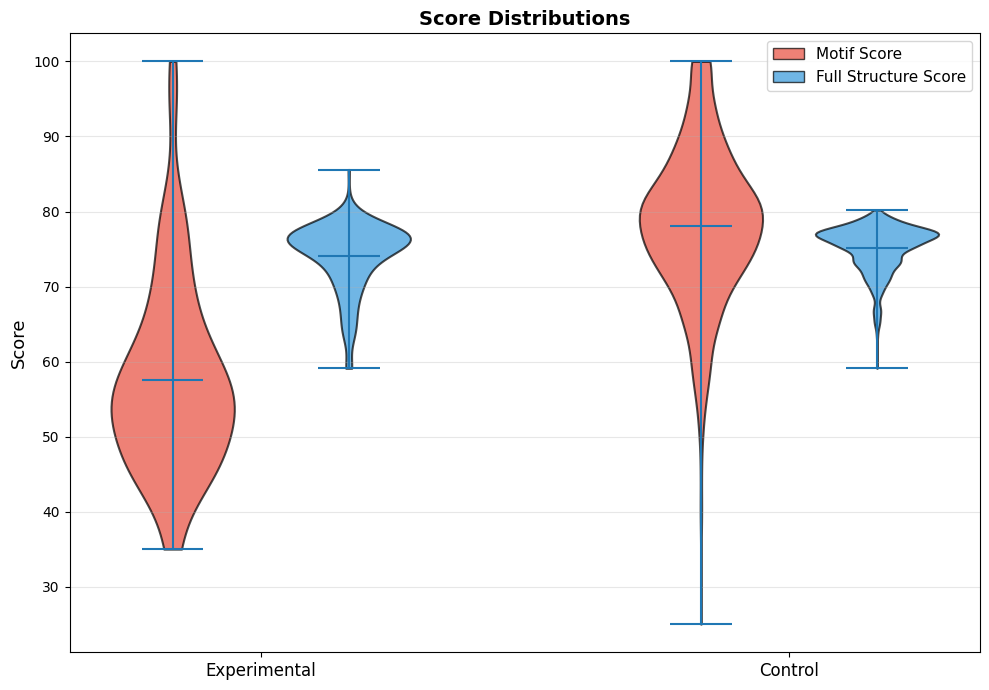

In [17]:
experimental_group = motifs_scores[motifs_scores['Motif_Name'].isin(motifs_df['motif_id'])]
control_group = motifs_scores[~motifs_scores['Motif_Name'].isin(motifs_df['motif_id'])]

fig, ax = plt.subplots(figsize=(10, 7))

data_to_plot = [
    experimental_group['Motif_Score'],
    experimental_group['Full_Structure_Score'],
    control_group['Motif_Score'],
    control_group['Full_Structure_Score']
]

positions = [1, 2, 4, 5]
colors = ['#e74c3c', '#3498db', '#e74c3c', '#3498db']

parts = ax.violinplot(data_to_plot, positions=positions, showmeans=True, showmedians=False, widths=0.7)

for pc, color in zip(parts['bodies'], colors):
    pc.set_facecolor(color)
    pc.set_alpha(0.7)
    pc.set_edgecolor('black')
    pc.set_linewidth(1.5)

ax.set_ylabel('Score', fontsize=13)
ax.set_title('Score Distributions', fontsize=14, fontweight='bold')
ax.set_xticks([1.5, 4.5])
ax.set_xticklabels(['Experimental', 'Control'], fontsize=12)
ax.grid(True, alpha=0.3, axis='y')

legend_elements = [
    Patch(facecolor='#e74c3c', alpha=0.7, edgecolor='black', label='Motif Score'),
    Patch(facecolor='#3498db', alpha=0.7, edgecolor='black', label='Full Structure Score')
]
ax.legend(handles=legend_elements, fontsize=11, loc='upper right')

plt.tight_layout()

#Conclussion
This algorithm has demonstrated that automated scoring of RNA base-pair geometry can reliably identify refinement targets, is independent of structure size, and provides complementary quality assessment to existing tools. This work establishes a foundation for systematic, quantitative RNA structure base-pair quality control, ultimately improving the reliability of structural data deposited in the Protein Data Bank.

# Future direction
The primary next step is to establish a data-driven baseline score or threshold below which we can confidently say a structure is poorly refined and needs attention.